# UTS GRAF SAINS DATA

**Nama:** Putri Ikrima Al Fadhilah  
**NIM:** 23031554133

## 1. Tugas Pendahuluan

### 1.2 Pertanyaan Pendahuluan (Checkpoint)

**1. Apa nama database yang digunakan pada tutorial ini?**

Database yang digunakan pada tutorial adalah `neo4j`, sebagaimana ditunjukkan pada parameter `database_="neo4j"` dalam kode Python. Pada implementasi tugas ini, database yang digunakan adalah `retailrocket`.

**2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan mengakses database lain dalam 1 instance!**

Akses database lain dalam satu instance Neo4j dapat dilakukan menggunakan perintah `:use nama_database` pada Neo4j Browser atau dengan menentukan nama database melalui Python Driver menggunakan `driver.session(database="nama_database")`.

Selain itu, Cypher menyediakan perintah seperti `CREATE`, `MERGE`, `MATCH`, `SET`, dan `DELETE` untuk mengelola data graf. Perintah `SHOW DATABASES` digunakan untuk menampilkan daftar database, sedangkan `CREATE DATABASE` digunakan untuk membuat database baru sesuai hak akses pengguna.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

Graf pertemanan yang dibuat merupakan graf berarah (*directed graph*) dengan model *property graph*. Graf terdiri atas empat simpul berlabel `Person`, yaitu Arthur, Guinevere, Lancelot, dan Merlin, serta tiga hubungan bertipe `KNOWS` yang mengarah dari Arthur menuju ketiga simpul lainnya. Hubungan tersebut bersifat berarah sehingga tidak otomatis berlaku sebaliknya.


## 2. Soal UTS

### 2.1 Wrangling dan EDA


#### 2.1.1 Penentuan Periode Waktu

Pengolahan data dimulai dengan membagi dataset RetailRocket menjadi dua periode, yaitu P1 sebagai data training dan P2 sebagai data testing. Pembagian ini dilakukan untuk memisahkan data yang digunakan dalam membangun model rekomendasi dengan data yang digunakan untuk menguji hasil rekomendasi.

Periode waktu yang digunakan adalah:

- **P1 (Training):** 2015-05-06 sampai sebelum 2015-06-05.
- **P2 (Testing):** 2015-09-02 sampai sebelum 2015-09-16.

P1 dipilih lebih awal daripada P2 agar proses pengolahan data mengikuti urutan waktu. Data interaksi pada P1 digunakan untuk membangun model rekomendasi, sedangkan data P2 digunakan untuk mengevaluasi hasilnya. Kedua periode tidak saling tumpang tindih sehingga data testing tidak ikut digunakan dalam proses training.



#### 2.1.2 Filter Data Berdasarkan Timestamp

Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!


In [2]:

import pandas as pd
from pathlib import Path
from urllib.request import urlretrieve
import zipfile

# 1. Menyiapkan dataset RetailRocket
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

csv_path = data_dir / "events.csv"
zip_path = Path("ecommerce-dataset.zip")

if not csv_path.exists():
    if not zip_path.exists():
        url = (
            "https://www.kaggle.com/api/v1/datasets/"
            "download/retailrocket/ecommerce-dataset"
        )
        print("Mengunduh dataset RetailRocket...")
        urlretrieve(url, zip_path)

    print("Mengekstrak events.csv...")
    with zipfile.ZipFile(zip_path, "r") as z:
        nama_file = next(
            (n for n in z.namelist()
             if Path(n).name == "events.csv"),
            None
        )
        if nama_file is None:
            raise FileNotFoundError(
                "events.csv tidak ditemukan dalam ZIP."
            )

        with z.open(nama_file) as sumber:
            import shutil
            with open(csv_path, "wb") as tujuan:
                shutil.copyfileobj(sumber, tujuan)

# 2. Membaca dataset
df = pd.read_csv(csv_path)

# 3. Mengubah timestamp Unix milidetik ke UTC
df["datetime"] = pd.to_datetime(
    df["timestamp"], unit="ms", utc=True
)

# 4. Menentukan periode P1 dan P2
p1_start = pd.Timestamp("2015-05-06", tz="UTC")
p1_end = pd.Timestamp("2015-06-05", tz="UTC")

p2_start = pd.Timestamp("2015-09-02", tz="UTC")
p2_end = pd.Timestamp("2015-09-16", tz="UTC")

# 5. Filter data berdasarkan periode
p1 = df[
    (df["datetime"] >= p1_start) &
    (df["datetime"] < p1_end)
].copy()

p2 = df[
    (df["datetime"] >= p2_start) &
    (df["datetime"] < p2_end)
].copy()

# 6. Menyimpan hasil filter ke CSV
p1.to_csv(data_dir / "events_p1.csv", index=False)
p2.to_csv(data_dir / "events_p2.csv", index=False)

# 7. Menampilkan ringkasan hasil
print("Jumlah data awal :", len(df))
print("Jumlah data P1   :", len(p1))
print("Jumlah data P2   :", len(p2))

print("\nRentang waktu P1:")
print(p1["datetime"].min(), "sampai",
      p1["datetime"].max())

print("\nRentang waktu P2:")
print(p2["datetime"].min(), "sampai",
      p2["datetime"].max())

print("\nFile CSV berhasil disimpan.")


Mengekstrak events.csv...
Jumlah data awal : 2756101
Jumlah data P1   : 627860
Jumlah data P2   : 262381

Rentang waktu P1:
2015-05-06 00:00:01.925000+00:00 sampai 2015-06-04 23:59:56.235000+00:00

Rentang waktu P2:
2015-09-02 00:00:10.579000+00:00 sampai 2015-09-15 23:59:58.763000+00:00

File CSV berhasil disimpan.



**Hasil dan Pembahasan**

Dari total 2.756.101 data interaksi RetailRocket, setelah dilakukan filter berdasarkan `timestamp`, diperoleh **627.860 interaksi pada P1 (training)** dan **262.381 interaksi pada P2 (testing)**, dengan total 890.241 interaksi.

Data P1 mencakup 6 Mei–4 Juni 2015, sedangkan P2 mencakup 2–15 September 2015. Hasil filter disimpan dalam file `events_p1.csv` dan `events_p2.csv`. Kedua data ini nantinya digunakan untuk membangun model rekomendasi dan mengevaluasi hasilnya.



#### 2.1.3 Komposisi Subgraph

Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!


In [3]:

from neo4j import GraphDatabase
from getpass import getpass
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm
import math

# Konfigurasi Neo4j
URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
DATABASE = "retailrocket"

PASSWORD = getpass("Masukkan password Neo4j: ")

# Membaca data P1 hasil filtering
csv_path = Path("data/events_p1.csv")
if not csv_path.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {csv_path}")

# Menggunakan kolom asli RetailRocket
df_p1 = pd.read_csv(
    csv_path,
    usecols=["timestamp", "visitorid", "event",
             "itemid", "transactionid"]
)

# Memastikan data yang diimpor valid
df_p1 = df_p1.dropna(
    subset=["timestamp", "visitorid", "event", "itemid"]
).copy()

df_p1["timestamp"] = df_p1["timestamp"].astype("int64")
df_p1["visitorid"] = df_p1["visitorid"].astype("int64")
df_p1["itemid"] = df_p1["itemid"].astype("int64")

df_p1["transactionid"] = (
    df_p1["transactionid"]
    .astype("Int64")
    .astype("string")
    .fillna("")
)

# Fungsi impor satu batch
def import_batch(tx, records):
    query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row

    FOREACH (_ IN CASE WHEN row.event = 'view'
                       THEN [1] ELSE [] END |
        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp
        }]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'addtocart'
                       THEN [1] ELSE [] END |
        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp
        }]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'transaction'
                       THEN [1] ELSE [] END |
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    )
    """
    tx.run(query, batch=records).consume()

# Membuat koneksi
driver = GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
)
driver.verify_connectivity()

batch_size = 2000
total_batches = math.ceil(len(df_p1) / batch_size)

try:
    with driver.session(database=DATABASE) as session:

        # Constraint untuk ID unik
        session.run("""
            CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
            FOR (v:Visitor)
            REQUIRE v.visitorId IS UNIQUE
        """).consume()

        session.run("""
            CREATE CONSTRAINT item_id_unique IF NOT EXISTS
            FOR (i:Item)
            REQUIRE i.itemId IS UNIQUE
        """).consume()

        print("Memulai impor data P1 ke Neo4j...")

        for start in tqdm(
            range(0, len(df_p1), batch_size),
            total=total_batches,
            desc="Impor P1"
        ):
            chunk = df_p1.iloc[start:start + batch_size]
            records = chunk.to_dict(orient="records")
            session.execute_write(import_batch, records)

        print("\nImpor data P1 berhasil!")

finally:
    driver.close()


Memulai impor data P1 ke Neo4j...


Impor P1:   0%|          | 0/314 [00:00<?, ?it/s]


Impor data P1 berhasil!


In [4]:

# Menghitung komposisi subgraph P1 menggunakan Neo4j

from neo4j import GraphDatabase
import pandas as pd

driver = GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
)

query = """
MATCH (n)
WHERE n:Visitor OR n:Item
RETURN labels(n)[0] AS jenis_simpul,
       count(n) AS jumlah_simpul
ORDER BY jenis_simpul
"""

with driver.session(database=DATABASE) as session:
    result = session.run(query)
    data = [dict(record) for record in result]

df_komposisi = pd.DataFrame(data)

print("Komposisi Subgraph P1:")
display(df_komposisi)

print("\nTotal simpul:",
      df_komposisi["jumlah_simpul"].sum())

driver.close()


Komposisi Subgraph P1:


,jenis_simpul,jumlah_simpul
0,Item,118508
1,Visitor,325964



Total simpul: 444472



**Hasil dan Pembahasan**

Hasil query Cypher menunjukkan bahwa subgraph P1 memiliki **325.964 simpul `Visitor`** dan **118.508 simpul `Item`**, sehingga totalnya sebanyak **444.472 simpul**.

Jumlah simpul `Visitor` lebih banyak dibandingkan `Item`, yang berarti jumlah pengunjung unik lebih banyak daripada produk unik pada periode P1. Query Cypher digunakan untuk menghitung jumlah simpul berdasarkan labelnya, kemudian hasilnya ditampilkan dalam bentuk DataFrame.

Subgraph ini selanjutnya digunakan untuk membentuk representasi vektor dan melakukan analisis proyeksi graf.


#### 2.1.4 Vector Space Modelling (VSM) User

Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [5]:

import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# Mengambil data interaksi P1
df_vsm = pd.read_csv("data/events_p1.csv")

# Mengambil pasangan User-Item yang unik
interaksi = df_vsm[
    ["visitorid", "itemid"]
].drop_duplicates().copy()

# Membuat indeks User dan Item
user_ids = np.sort(interaksi["visitorid"].unique())
item_ids = np.sort(interaksi["itemid"].unique())

user_index = pd.Index(user_ids)
item_index = pd.Index(item_ids)

# Mengubah ID menjadi indeks matriks
rows = user_index.get_indexer(interaksi["visitorid"])
cols = item_index.get_indexer(interaksi["itemid"])

# Membentuk sparse matrix User-Item
X_user = csr_matrix(
    (
        np.ones(len(interaksi), dtype=np.uint8),
        (rows, cols)
    ),
    shape=(len(user_ids), len(item_ids))
)

# Menampilkan karakteristik matriks
print("=== VSM USER ===")
print("Jumlah User :", len(user_ids))
print("Jumlah Item :", len(item_ids))
print("Shape       :", X_user.shape)
print("Dimensi     :", X_user.ndim)
print("Non-zero    :", X_user.nnz)
print("Sparsity    :",
      round((1 - X_user.nnz /
      (X_user.shape[0] * X_user.shape[1])) * 100, 4), "%")


=== VSM USER ===
Jumlah User : 325964
Jumlah Item : 118508
Shape       : (325964, 118508)
Dimensi     : 2
Non-zero    : 487584
Sparsity    : 99.9987 %


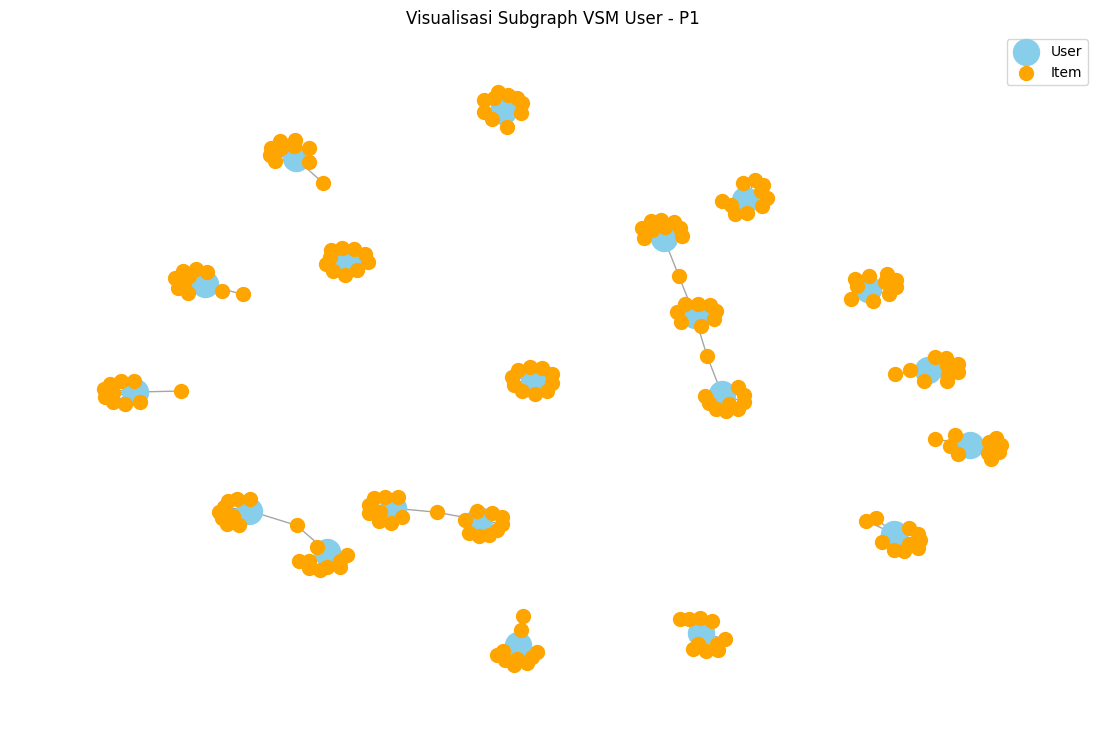

Jumlah node sampel : 216
Jumlah edge sampel : 200


In [6]:

import networkx as nx
import matplotlib.pyplot as plt

# Mengambil sampel 20 user dengan interaksi terbanyak
top_users = (
    interaksi["visitorid"]
    .value_counts()
    .head(20)
    .index
)

sample = interaksi[
    interaksi["visitorid"].isin(top_users)
].copy()

# Membatasi jumlah item untuk visualisasi
sample = sample.groupby("visitorid").head(10)

# Membentuk graf bipartit
G = nx.Graph()

for _, row in sample.iterrows():
    user = f"U_{row['visitorid']}"
    item = f"I_{row['itemid']}"

    G.add_node(user, bipartite=0)
    G.add_node(item, bipartite=1)
    G.add_edge(user, item)

# Mengatur posisi simpul
pos = nx.spring_layout(G, seed=42)

user_nodes = [
    n for n, d in G.nodes(data=True)
    if d["bipartite"] == 0
]

item_nodes = [
    n for n, d in G.nodes(data=True)
    if d["bipartite"] == 1
]

plt.figure(figsize=(14, 9))

nx.draw_networkx_nodes(
    G, pos,
    nodelist=user_nodes,
    node_color="skyblue",
    node_size=350,
    label="User"
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=100,
    label="Item"
)

nx.draw_networkx_edges(
    G, pos,
    alpha=0.35
)

plt.title("Visualisasi Subgraph VSM User - P1")
plt.legend()
plt.axis("off")
plt.show()

print("Jumlah node sampel :", G.number_of_nodes())
print("Jumlah edge sampel :", G.number_of_edges())


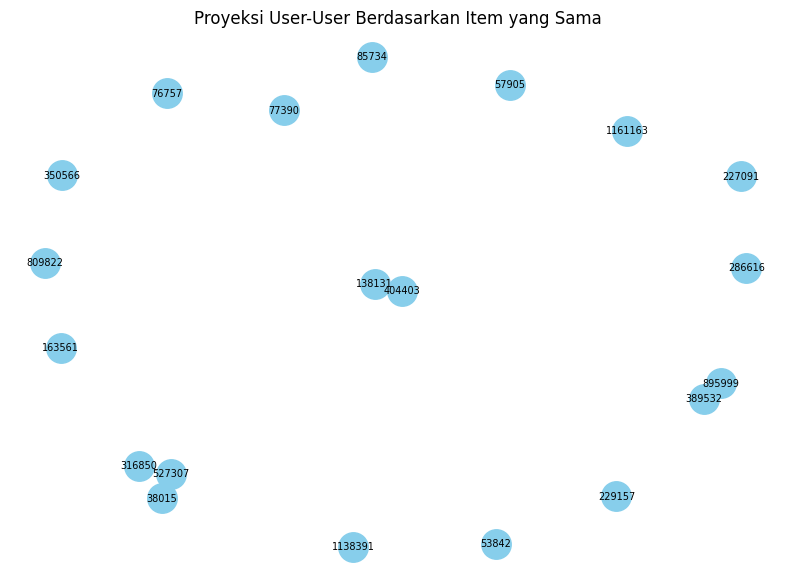

Jumlah node User: 20
Jumlah edge User-User: 4


In [9]:

import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from itertools import combinations

# Menggunakan sampel User-Item dari nomor 4
# Variabel sample sudah dibuat sebelumnya

# Membentuk proyeksi User-User
G_user_projection = nx.Graph()

# Menambahkan semua User dari sampel
for user_id in sample["visitorid"].unique():
    G_user_projection.add_node(int(user_id))

# Mengelompokkan User berdasarkan Item yang sama
for item_id, group in sample.groupby("itemid"):
    users = group["visitorid"].unique()

    # Menghubungkan User yang berinteraksi dengan Item sama
    for u1, u2 in combinations(users, 2):
        u1, u2 = int(u1), int(u2)

        if G_user_projection.has_edge(u1, u2):
            G_user_projection[u1][u2]["weight"] += 1
        else:
            G_user_projection.add_edge(
                u1, u2, weight=1
            )

# Visualisasi
plt.figure(figsize=(10, 7))

pos = nx.spring_layout(
    G_user_projection, seed=42
)

nx.draw_networkx(
    G_user_projection,
    pos,
    with_labels=True,
    node_color="skyblue",
    node_size=450,
    font_size=7,
    edge_color="gray"
)

plt.title("Proyeksi User-User Berdasarkan Item yang Sama")
plt.axis("off")
plt.show()

print("Jumlah node User:",
      G_user_projection.number_of_nodes())

print("Jumlah edge User-User:",
      G_user_projection.number_of_edges())


In [12]:

from neo4j import GraphDatabase
import pandas as pd

# Mengambil ID User dari sampel VSM User
sample_user_ids = [
    int(x) for x in sample["visitorid"].unique()
]

query_user = """
MATCH (u1:Visitor)-[]->(i:Item)<-[]-(u2:Visitor)
WHERE u1.visitorId IN $user_ids
  AND u2.visitorId IN $user_ids
  AND u1.visitorId < u2.visitorId
WITH u1, u2, count(DISTINCT i) AS common_items
RETURN u1.visitorId AS user_1,
       u2.visitorId AS user_2,
       common_items
ORDER BY common_items DESC, user_1, user_2
LIMIT 10
"""

with GraphDatabase.driver(
    URI, auth=(USER, PASSWORD)
) as driver:
    with driver.session(database=DATABASE) as session:
        result = session.run(
            query_user,
            user_ids=sample_user_ids
        )
        hasil_user = [dict(r) for r in result]

df_query_user = pd.DataFrame(
    hasil_user,
    columns=["user_1", "user_2", "common_items"]
)

print("Hasil Query Cypher User-User:")
display(df_query_user)


Hasil Query Cypher User-User:


,user_1,user_2,common_items
0,163561,286616,165
1,286616,350566,124
2,163561,350566,122
3,286616,389532,97
4,57905,163561,85
5,57905,286616,84
6,138131,286616,81
7,286616,1161163,76
8,163561,1161163,73
9,138131,163561,72



**Hasil dan Pembahasan**

Hasil VSM User pada P1 menghasilkan matriks User–Item berukuran **(325964, 118508)** dengan **487.584 elemen non-zero**. Nilai *sparsity* sebesar **99,9987%** menunjukkan bahwa sebagian besar pengguna tidak berinteraksi dengan semua produk.

Visualisasi graf bipartit menggunakan NetworkX menghasilkan **216 simpul dan 200 sisi**, sedangkan proyeksi User–User menghasilkan **20 simpul dan 4 sisi**. Hal ini menunjukkan bahwa hanya beberapa pengguna dalam sampel yang memiliki interaksi dengan produk yang sama.

Dari query Cypher di Neo4j, pasangan User 163561 dan 286616 memiliki **165 produk bersama**, sedangkan User 286616 dan 350566 memiliki **124 produk bersama**. Hasil NetworkX dan Neo4j berbeda karena NetworkX hanya menggunakan sampel, sedangkan Neo4j menggunakan data interaksi P1 yang lebih lengkap. Hasil ini digunakan untuk melihat kemiripan antar pengguna berdasarkan produk yang sama.


#### 2.1.5 Vector Space Modelling (VSM) Item

Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (di-mensi, shape, plot networkx, dst.)!

In [7]:

# Membentuk VSM Item dari transpose matriks User-Item
X_item = X_user.T.tocsr()

# Menampilkan karakteristik VSM Item
print("=== VSM ITEM ===")
print("Jumlah Item :", X_item.shape[0])
print("Jumlah User :", X_item.shape[1])
print("Shape       :", X_item.shape)
print("Dimensi     :", X_item.ndim)
print("Non-zero    :", X_item.nnz)

sparsity_item = (
    1 - X_item.nnz /
    (X_item.shape[0] * X_item.shape[1])
) * 100

print("Sparsity    :", round(sparsity_item, 4), "%")


=== VSM ITEM ===
Jumlah Item : 118508
Jumlah User : 325964
Shape       : (118508, 325964)
Dimensi     : 2
Non-zero    : 487584
Sparsity    : 99.9987 %


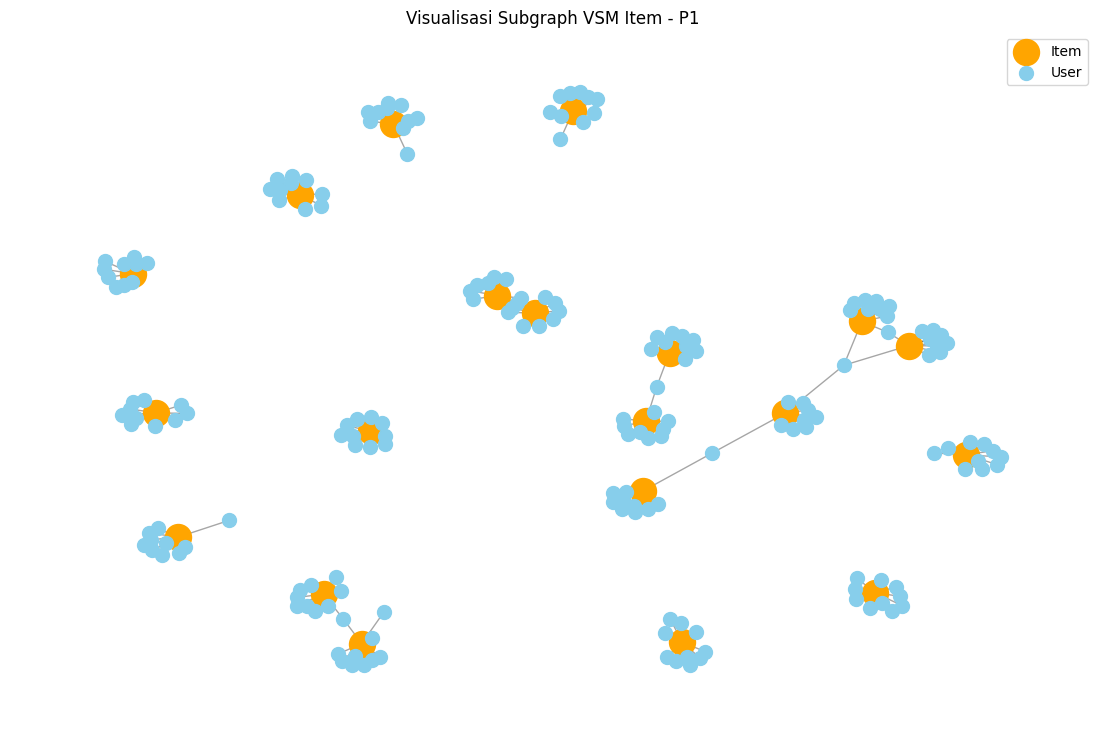

Jumlah node sampel : 210
Jumlah edge sampel : 200


In [8]:

import networkx as nx
import matplotlib.pyplot as plt

# Mengambil 20 item dengan interaksi pengguna terbanyak
top_items = (
    interaksi["itemid"]
    .value_counts()
    .head(20)
    .index
)

sample_item = interaksi[
    interaksi["itemid"].isin(top_items)
].copy()

# Maksimal 10 user untuk setiap item
sample_item = sample_item.groupby("itemid").head(10)

# Membentuk graf bipartit
G_item = nx.Graph()

for _, row in sample_item.iterrows():
    user = f"U_{row['visitorid']}"
    item = f"I_{row['itemid']}"

    G_item.add_node(user, bipartite=0)
    G_item.add_node(item, bipartite=1)
    G_item.add_edge(item, user)

# Mengatur posisi simpul
pos_item = nx.spring_layout(G_item, seed=42)

user_nodes_item = [
    n for n, d in G_item.nodes(data=True)
    if d["bipartite"] == 0
]

item_nodes_item = [
    n for n, d in G_item.nodes(data=True)
    if d["bipartite"] == 1
]

plt.figure(figsize=(14, 9))

nx.draw_networkx_nodes(
    G_item, pos_item,
    nodelist=item_nodes_item,
    node_color="orange",
    node_size=350,
    label="Item"
)

nx.draw_networkx_nodes(
    G_item, pos_item,
    nodelist=user_nodes_item,
    node_color="skyblue",
    node_size=100,
    label="User"
)

nx.draw_networkx_edges(
    G_item, pos_item,
    alpha=0.35
)

plt.title("Visualisasi Subgraph VSM Item - P1")
plt.legend()
plt.axis("off")
plt.show()

print("Jumlah node sampel :", G_item.number_of_nodes())
print("Jumlah edge sampel :", G_item.number_of_edges())


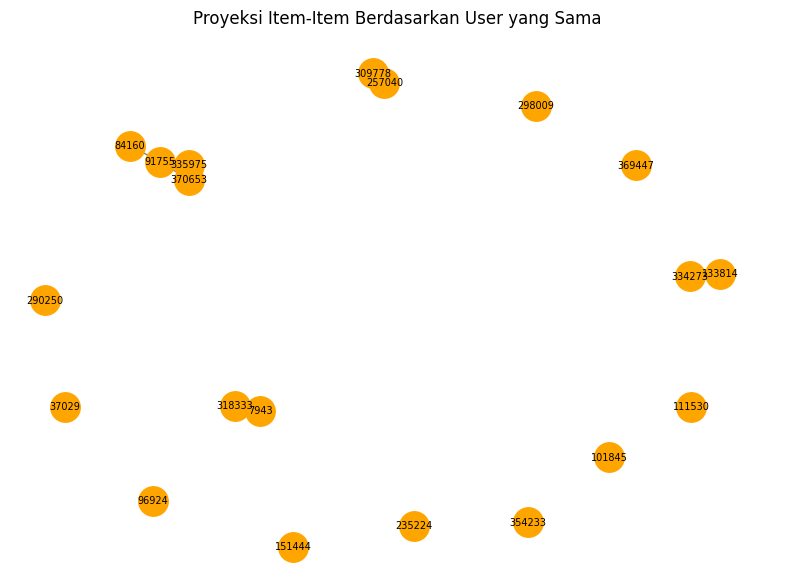

Jumlah node Item: 20
Jumlah edge Item-Item: 7


In [10]:

import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations

# Menggunakan sample_item dari nomor 5

G_item_projection = nx.Graph()

# Menambahkan seluruh Item pada sampel
for item_id in sample_item["itemid"].unique():
    G_item_projection.add_node(int(item_id))

# Mengelompokkan Item berdasarkan User yang sama
for user_id, group in sample_item.groupby("visitorid"):
    items = group["itemid"].unique()

    # Menghubungkan Item yang diakses User sama
    for i1, i2 in combinations(items, 2):
        i1, i2 = int(i1), int(i2)

        if G_item_projection.has_edge(i1, i2):
            G_item_projection[i1][i2]["weight"] += 1
        else:
            G_item_projection.add_edge(
                i1, i2, weight=1
            )

# Visualisasi
plt.figure(figsize=(10, 7))

pos_item_projection = nx.spring_layout(
    G_item_projection, seed=42
)

nx.draw_networkx(
    G_item_projection,
    pos_item_projection,
    with_labels=True,
    node_color="orange",
    node_size=450,
    font_size=7,
    edge_color="gray"
)

plt.title("Proyeksi Item-Item Berdasarkan User yang Sama")
plt.axis("off")
plt.show()

print("Jumlah node Item:",
      G_item_projection.number_of_nodes())

print("Jumlah edge Item-Item:",
      G_item_projection.number_of_edges())


In [13]:

# Mengambil ID Item dari sampel VSM Item
sample_item_ids = [
    int(x) for x in sample_item["itemid"].unique()
]

query_item = """
MATCH (i1:Item)<-[]-(u:Visitor)-[]->(i2:Item)
WHERE i1.itemId IN $item_ids
  AND i2.itemId IN $item_ids
  AND i1.itemId < i2.itemId
WITH i1, i2, count(DISTINCT u) AS common_users
RETURN i1.itemId AS item_1,
       i2.itemId AS item_2,
       common_users
ORDER BY common_users DESC, item_1, item_2
LIMIT 10
"""

with GraphDatabase.driver(
    URI, auth=(USER, PASSWORD)
) as driver:
    with driver.session(database=DATABASE) as session:
        result = session.run(
            query_item,
            item_ids=sample_item_ids
        )
        hasil_item = [dict(r) for r in result]

df_query_item = pd.DataFrame(
    hasil_item,
    columns=["item_1", "item_2", "common_users"]
)

print("Hasil Query Cypher Item-Item:")
display(df_query_item)


Hasil Query Cypher Item-Item:


,item_1,item_2,common_users
0,257040,309778,64
1,84160,370653,53
2,335975,370653,52
3,91755,335975,34
4,91755,370653,29
5,84160,335975,23
6,84160,91755,18
7,37029,369447,16
8,7943,369447,10
9,133814,334273,10


In [15]:
print("Jumlah node Item:", G_item_projection.number_of_nodes())
print("Jumlah edge Item-Item:", G_item_projection.number_of_edges())

Jumlah node Item: 20
Jumlah edge Item-Item: 7



**Hasil dan Pembahasan**

Hasil VSM Item pada P1 menghasilkan matriks Item–User berukuran **(118508, 325964)** dengan **487.584 elemen non-zero**. Nilai *sparsity* sebesar **99,9987%** menunjukkan bahwa sebagian besar produk tidak memiliki interaksi dengan semua pengguna.

Visualisasi graf bipartit menggunakan NetworkX menghasilkan **210 simpul dan 200 sisi**, sedangkan proyeksi Item–Item menghasilkan **20 simpul dan 7 sisi**. Hal ini menunjukkan bahwa beberapa produk dalam sampel memiliki pengguna yang sama.

Dari hasil query Cypher di Neo4j, Item 257040 dan 309778 memiliki **64 pengguna bersama**, Item 84160 dan 370653 memiliki **53 pengguna bersama**, serta Item 335975 dan 370653 memiliki **52 pengguna bersama**. Hasil ini menunjukkan adanya kesamaan interaksi antarproduk yang dapat digunakan untuk menghitung kemiripan produk dalam sistem rekomendasi.


#### 2.1.6 Perbandingan Proyeksi User–User dan Item–Item

Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

In [16]:

import networkx as nx
import pandas as pd
import time

# Mengukur waktu pembentukan ulang proyeksi dari sampel
from itertools import combinations

def buat_proyeksi_user(data):
    G = nx.Graph()
    G.add_nodes_from(data["visitorid"].astype(int).unique())

    for _, group in data.groupby("itemid"):
        users = group["visitorid"].astype(int).unique()

        for u1, u2 in combinations(users, 2):
            if G.has_edge(u1, u2):
                G[u1][u2]["weight"] += 1
            else:
                G.add_edge(u1, u2, weight=1)

    return G

def buat_proyeksi_item(data):
    G = nx.Graph()
    G.add_nodes_from(data["itemid"].astype(int).unique())

    for _, group in data.groupby("visitorid"):
        items = group["itemid"].astype(int).unique()

        for i1, i2 in combinations(items, 2):
            if G.has_edge(i1, i2):
                G[i1][i2]["weight"] += 1
            else:
                G.add_edge(i1, i2, weight=1)

    return G

# Mengukur waktu proyeksi User
start = time.perf_counter()
G_user_test = buat_proyeksi_user(sample)
waktu_user = time.perf_counter() - start

# Mengukur waktu proyeksi Item
start = time.perf_counter()
G_item_test = buat_proyeksi_item(sample_item)
waktu_item = time.perf_counter() - start

# Membuat tabel perbandingan
hasil_perbandingan = pd.DataFrame({
    "Karakteristik": [
        "Jumlah Simpul",
        "Jumlah Sisi",
        "Density",
        "Waktu Komputasi (detik)"
    ],
    "User-User": [
        G_user_test.number_of_nodes(),
        G_user_test.number_of_edges(),
        round(nx.density(G_user_test), 6),
        round(waktu_user, 6)
    ],
    "Item-Item": [
        G_item_test.number_of_nodes(),
        G_item_test.number_of_edges(),
        round(nx.density(G_item_test), 6),
        round(waktu_item, 6)
    ]
})

print("=== PERBANDINGAN PROYEKSI ===")
display(hasil_perbandingan)


=== PERBANDINGAN PROYEKSI ===


,Karakteristik,User-User,Item-Item
0,Jumlah Simpul,20.000000,20.000000
1,Jumlah Sisi,4.000000,7.000000
2,Density,0.021053,0.036842
3,Waktu Komputasi (detik),0.041318,0.024007



**Hasil dan Pembahasan**

Hasil perbandingan menunjukkan bahwa kedua proyeksi memiliki **20 simpul**. Proyeksi User–User menghasilkan **4 sisi** dengan *density* **0,021053**, sedangkan Item–Item menghasilkan **7 sisi** dengan *density* **0,036842**. Artinya, proyeksi Item–Item memiliki hubungan yang lebih banyak pada sampel yang digunakan.

Dari waktu komputasi, proyeksi User–User membutuhkan **0,041318 detik**, sedangkan Item–Item **0,024007 detik**. Jadi, proyeksi Item–Item lebih cepat dalam pengujian ini.

Oleh karena itu, **proyeksi Item–Item dipilih untuk analisis selanjutnya** karena memiliki keterhubungan lebih tinggi dan waktu komputasi lebih singkat pada sampel. Namun, hasil ini belum menunjukkan bahwa rekomendasinya lebih akurat, sehingga perlu dievaluasi menggunakan Hit@5 dan NDCG@5.


#### 2.1.7 Perhitungan Similarity Item–Item

Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggu-nakan Python

In [17]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize
from scipy.sparse import csr_matrix

# Menggunakan VSM Item dari nomor 5
# X_item: matriks Item-User
# item_ids: daftar ID Item sesuai urutan matriks

# Normalisasi setiap vektor Item
X_item_norm = normalize(
    X_item.astype(np.float32),
    norm="l2",
    axis=1
).tocsr()

# Memilih Item acuan secara reproducible
# Dipilih dari 100 Item dengan pengguna unik terbanyak
jumlah_user_item = np.diff(X_item.indptr)

top_100_idx = np.argsort(
    -jumlah_user_item,
    kind="stable"
)[:100]

rng = np.random.default_rng(42)
idx_acuan = int(rng.choice(top_100_idx))
item_acuan = int(item_ids[idx_acuan])

# Menghitung cosine similarity Item acuan
# terhadap seluruh Item dalam VSM P1
similarity = (
    X_item_norm[idx_acuan] @ X_item_norm.T
).tocsr()

# Mengambil pasangan dengan similarity positif
indices = similarity.indices
scores = similarity.data

# Menghilangkan Item acuan itu sendiri
mask = indices != idx_acuan
indices = indices[mask]
scores = scores[mask]

# Mengurutkan berdasarkan similarity tertinggi
urutan = np.lexsort((item_ids[indices], -scores))
top_indices = indices[urutan[:5]]
top_scores = scores[urutan[:5]]

df_similarity = pd.DataFrame({
    "item_acuan": item_acuan,
    "item_mirip": item_ids[top_indices].astype(int),
    "cosine_similarity": np.round(top_scores, 6)
})

print("=== COSINE SIMILARITY ITEM-ITEM ===")
print("Item acuan:", item_acuan)
print("Jumlah kandidat similarity positif:", len(indices))
print("\n5 Item dengan similarity tertinggi:")
display(df_similarity)


=== COSINE SIMILARITY ITEM-ITEM ===
Item acuan: 133814
Jumlah kandidat similarity positif: 884

5 Item dengan similarity tertinggi:


,item_acuan,item_mirip,cosine_similarity
0,133814,323194,0.092558
1,133814,378637,0.075763
2,133814,185,0.056796
3,133814,1766,0.056796
4,133814,2759,0.056796


#### 2.1.7(a) Menampilkan 5 Record Similarity Tertinggi

(a)	Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

In [18]:

from neo4j import GraphDatabase

# Mengubah hasil similarity menjadi daftar record
records_similarity = [
    {
        "item_acuan": int(row["item_acuan"]),
        "item_mirip": int(row["item_mirip"]),
        "score": float(row["cosine_similarity"])
    }
    for _, row in df_similarity.iterrows()
]

query_simpan = """
UNWIND $records AS row
MATCH (a:Item {itemId: row.item_acuan})
MATCH (b:Item {itemId: row.item_mirip})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.score = row.score,
    r.method = 'cosine',
    r.period = 'P1'
RETURN count(r) AS jumlah_similarity
"""

with GraphDatabase.driver(
    URI, auth=(USER, PASSWORD)
) as driver:
    with driver.session(database=DATABASE) as session:
        result = session.run(
            query_simpan,
            records=records_similarity
        )
        jumlah = result.single()["jumlah_similarity"]

print("=== PENYIMPANAN SIMILARITY ===")
print("Jumlah relationship diproses:", jumlah)
print("Similarity berhasil disimpan ke Neo4j.")


=== PENYIMPANAN SIMILARITY ===
Jumlah relationship diproses: 5
Similarity berhasil disimpan ke Neo4j.


In [21]:
# Soal 2.1.7(a)
# Menampilkan 5 record similarity tertinggi dari Neo4j

query_top5 = """
MATCH (a:Item {itemId: 133814})-[r:SIMILAR_TO]->(b:Item)
WHERE r.method = 'cosine'
  AND r.period = 'P1'
RETURN a.itemId AS item_acuan,
       b.itemId AS item_mirip,
       r.score AS cosine_similarity
ORDER BY cosine_similarity DESC, item_mirip
LIMIT 5
"""

with GraphDatabase.driver(
    URI, auth=(USER, PASSWORD)
) as driver:
    with driver.session(database=DATABASE) as session:
        result = session.run(query_top5)
        hasil_top5 = [dict(record) for record in result]

df_top5_neo4j = pd.DataFrame(hasil_top5)

print("=== HASIL QUERY CYPHER 7(a) ===")
display(df_top5_neo4j)


=== HASIL QUERY CYPHER 7(a) ===


,item_acuan,item_mirip,cosine_similarity
0,133814,323194,0.092558
1,133814,378637,0.075763
2,133814,185,0.056796
3,133814,1766,0.056796
4,133814,2759,0.056796


**Hasil dan Pembahasan 7(a)**

Hasil query Cypher pada Neo4j menunjukkan lima produk dengan nilai Cosine Similarity tertinggi terhadap Item 133814, yaitu Item 323194 sebesar **0,092558**, Item 378637 sebesar **0,075763**, serta Item 185, 1766, dan 2759 dengan nilai masing-masing **0,056796**.

Query menggunakan `MATCH` untuk mengambil hubungan `SIMILAR_TO`, `ORDER BY` untuk mengurutkan nilai similarity dari tertinggi, dan `LIMIT 5` untuk menampilkan lima record. Nilai similarity yang relatif rendah menunjukkan bahwa pola interaksi pengguna antarproduk memiliki tingkat kemiripan yang terbatas. Hasil query sesuai dengan perhitungan Python dan membuktikan bahwa kelima nilai similarity telah tersimpan pada Neo4j.

#### 2.1.7(b) Visualisasi Graf Similarity

(b)	Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-nya!

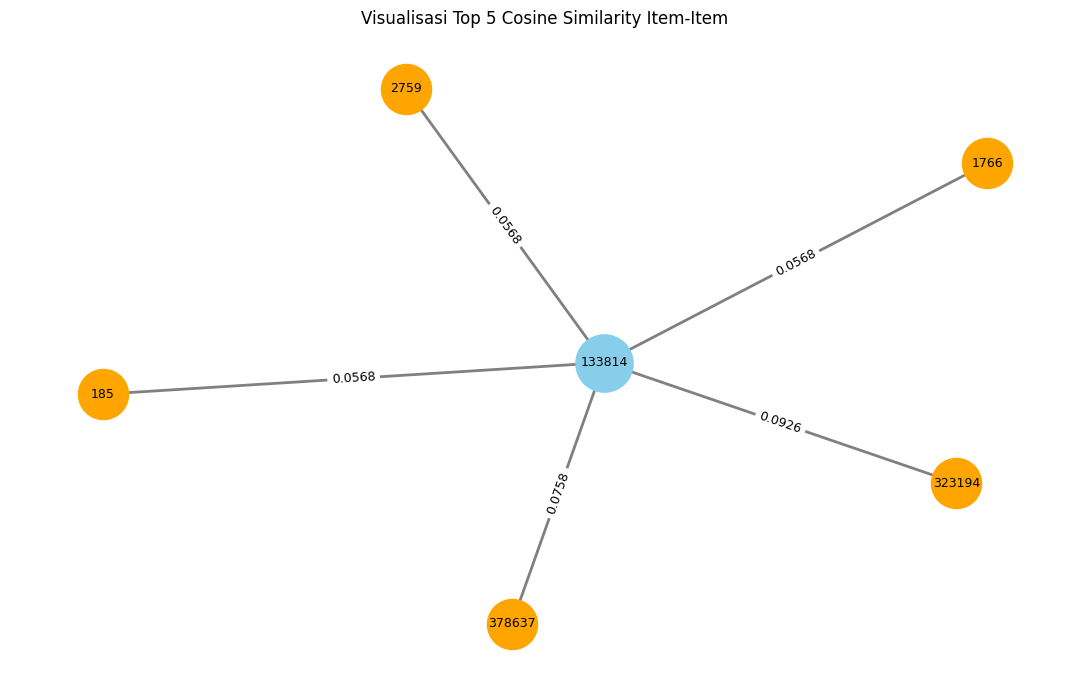

Jumlah simpul: 6
Jumlah sisi: 5


In [22]:

# Soal 2.1.7(b) - Visualisasi Similarity Item-Item

import networkx as nx
import matplotlib.pyplot as plt

G_similarity = nx.Graph()

for _, row in df_top5_neo4j.iterrows():
    item_a = int(row["item_acuan"])
    item_b = int(row["item_mirip"])
    score = float(row["cosine_similarity"])

    G_similarity.add_edge(
        item_a, item_b, weight=score
    )

pos = nx.spring_layout(G_similarity, seed=42)

plt.figure(figsize=(11, 7))

nx.draw_networkx_nodes(
    G_similarity, pos,
    nodelist=[133814],
    node_color="skyblue",
    node_size=1700
)

nx.draw_networkx_nodes(
    G_similarity, pos,
    nodelist=[n for n in G_similarity.nodes()
              if n != 133814],
    node_color="orange",
    node_size=1300
)

nx.draw_networkx_edges(
    G_similarity, pos,
    width=2,
    edge_color="gray"
)

nx.draw_networkx_labels(
    G_similarity, pos,
    font_size=9
)

edge_labels = {
    (u, v): f"{d['weight']:.4f}"
    for u, v, d in G_similarity.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G_similarity, pos,
    edge_labels=edge_labels,
    font_size=9
)

plt.title("Visualisasi Top 5 Cosine Similarity Item-Item")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah simpul:", G_similarity.number_of_nodes())
print("Jumlah sisi:", G_similarity.number_of_edges())


**Hasil dan Pembahasan 7(b)**

Visualisasi Cosine Similarity menggunakan NetworkX menghasilkan **6 simpul dan 5 sisi**, dengan Item 133814 sebagai simpul acuan yang terhubung dengan lima produk. Nilai similarity tertinggi sebesar **0,092558** terdapat pada Item 323194, sedangkan nilai terendah sebesar **0,056796** terdapat pada Item 185, 1766, dan 2759.

Visualisasi langsung pada Neo4j juga menunjukkan **6 simpul dan 5 relationship `SIMILAR_TO`**, yang membuktikan bahwa hasil perhitungan similarity telah tersimpan dalam database graf. Nilai similarity disimpan sebagai properti `score` pada masing-masing relationship dan dapat digunakan untuk analisis rekomendasi berbasis Item.


**Visualisasi Graf Similarity pada Neo4j**

![Graf Similarity Neo4j](graf_similarity_neo4j.png)



#### 2.1.8 Perbandingan Graf Sebelum dan Sesudah Perhitungan Similarity

Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

In [23]:

# Soal 2.1.8
# Query Cypher - Graf Sebelum Similarity

query_sebelum = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE i.itemId = 133814
  AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
WITH v, r, i
ORDER BY v.visitorId
LIMIT 30
RETURN v.visitorId AS visitor_id,
       type(r) AS interaksi,
       i.itemId AS item_id
"""

with GraphDatabase.driver(
    URI, auth=(USER, PASSWORD)
) as driver:
    with driver.session(database=DATABASE) as session:
        hasil_sebelum = [
            dict(record)
            for record in session.run(query_sebelum)
        ]

df_sebelum = pd.DataFrame(hasil_sebelum)

print("=== QUERY CYPHER SEBELUM SIMILARITY ===")
display(df_sebelum)

print("Jumlah interaksi ditampilkan:", len(df_sebelum))


=== QUERY CYPHER SEBELUM SIMILARITY ===


,visitor_id,interaksi,item_id
0,982,VIEWED,133814
1,1230,VIEWED,133814
2,2777,VIEWED,133814
3,2919,VIEWED,133814
4,13599,VIEWED,133814
5,14344,VIEWED,133814
6,15174,VIEWED,133814
7,17207,VIEWED,133814
8,17207,VIEWED,133814
9,27887,VIEWED,133814


Jumlah interaksi ditampilkan: 30



**Visualisasi Graf Sebelum Similarity**

![Graf Sebelum Similarity](sebelumm.png)


In [24]:

# Soal 2.1.8
# Query Cypher - Graf Sesudah Similarity

query_sesudah = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE i.itemId = 133814
  AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
WITH v, r, i
ORDER BY v.visitorId
LIMIT 30

WITH collect({
    visitor_id: v.visitorId,
    interaksi: type(r),
    item_id: i.itemId
}) AS interaksi_asli

MATCH (a:Item {itemId: 133814})-[s:SIMILAR_TO]->(b:Item)
WHERE s.period = 'P1'
  AND s.method = 'cosine'

RETURN a.itemId AS item_acuan,
       b.itemId AS item_mirip,
       s.score AS similarity,
       size(interaksi_asli) AS jumlah_interaksi_asli
ORDER BY similarity DESC
"""

with GraphDatabase.driver(
    URI, auth=(USER, PASSWORD)
) as driver:
    with driver.session(database=DATABASE) as session:
        hasil_sesudah = [
            dict(record)
            for record in session.run(query_sesudah)
        ]

df_sesudah = pd.DataFrame(hasil_sesudah)

print("=== QUERY CYPHER SESUDAH SIMILARITY ===")
display(df_sesudah)

print("Jumlah hubungan similarity:",
      len(df_sesudah))


=== QUERY CYPHER SESUDAH SIMILARITY ===


,item_acuan,item_mirip,similarity,jumlah_interaksi_asli
0,133814,323194,0.092558,30
1,133814,378637,0.075763,30
2,133814,2759,0.056796,30
3,133814,1766,0.056796,30
4,133814,185,0.056796,30


Jumlah hubungan similarity: 5



**Visualisasi Graf Sesudah Similarity**

![Graf Sesudah Similarity](sesudah.png)


**Hasil dan Pembahasan**

Sebelum perhitungan similarity, graf Neo4j menunjukkan hubungan interaksi asli antara simpul `Visitor` dan `Item`, tanpa menampilkan hubungan kemiripan antarproduk.

Setelah perhitungan Cosine Similarity, graf menampilkan tambahan **5 relationship `SIMILAR_TO`** yang menghubungkan Item 133814 dengan lima produk lainnya. Nilai similarity tertinggi sebesar **0,092558** terdapat pada Item 323194. Penambahan hubungan ini memperkaya struktur graf dengan informasi kemiripan antarproduk tanpa mengubah hubungan interaksi asli, sehingga dapat digunakan sebagai dasar rekomendasi berbasis Item.

### 2.2 Analytics

#### 2.2.1 Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

(a)	tuliskan skrip Python dalam merekomendasikan KNN-nya!

In [32]:

# Revisi pemilihan User untuk rekomendasi dan evaluasi
# User harus aktif pada P1 dan memiliki data aktual P2

import numpy as np

rng = np.random.default_rng(42)

# Jumlah Item unik setiap User pada P1
jumlah_item_user = np.asarray(
    X_item.getnnz(axis=0)
).ravel()

# User yang memiliki minimal 5 Item pada P1
user_aktif_idx = np.flatnonzero(
    jumlah_item_user >= 5
)

# User yang memiliki interaksi pada P2
user_p2 = set(
    df_p2["visitorid"].dropna().astype(int)
)

# Kandidat User yang memenuhi kedua syarat
kandidat_idx = [
    int(idx)
    for idx in user_aktif_idx
    if int(user_ids[idx]) in user_p2
]

if len(kandidat_idx) == 0:
    raise ValueError(
        "Tidak ditemukan User yang memenuhi kedua syarat."
    )

# Pemilihan acak yang dapat direproduksi
idx_user = int(rng.choice(kandidat_idx))
user_terpilih = int(user_ids[idx_user])

# Riwayat Item User pada P1
item_dilihat_idx = X_item[:, idx_user].nonzero()[0]

print("=== PEMILIHAN USER UNTUK EVALUASI ===")
print("Random seed:", 42)
print("User terpilih:", user_terpilih)
print("Jumlah Item P1:", len(item_dilihat_idx))
print("Jumlah interaksi P2:",
      len(df_p2[df_p2["visitorid"] == user_terpilih]))
print("Jumlah kandidat User:", len(kandidat_idx))


=== PEMILIHAN USER UNTUK EVALUASI ===
Random seed: 42
User terpilih: 130999
Jumlah Item P1: 60
Jumlah interaksi P2: 7
Jumlah kandidat User: 354


(b)	berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [38]:

# Soal 2.2.1(b) - Revisi Rekomendasi Item-Based KNN
# k = 5, User = 130999

from collections import defaultdict
import numpy as np
import pandas as pd

k = 5
skor_rekomendasi = defaultdict(float)

# Item yang sudah pernah diinteraksikan User pada P1
item_riwayat = set(map(int, item_dilihat_idx))

# Jumlah tetangga yang diperiksa
# Memperhitungkan Item riwayat yang harus dikeluarkan
n_neighbors = min(
    X_item.shape[0],
    len(item_riwayat) + k
)

# Mencari 5 tetangga valid untuk setiap Item riwayat
for idx_item in sorted(item_riwayat):

    distances, neighbors = model_knn.kneighbors(
        X_item[idx_item],
        n_neighbors=n_neighbors
    )

    jumlah_tetangga = 0

    for distance, idx_tetangga in zip(
        distances[0], neighbors[0]
    ):
        idx_tetangga = int(idx_tetangga)

        # Menghindari Item yang sudah ada dalam riwayat
        if idx_tetangga in item_riwayat:
            continue

        similarity = max(0.0, 1.0 - float(distance))

        # Hanya menggunakan similarity positif
        if similarity <= 0:
            continue

        skor_rekomendasi[idx_tetangga] += similarity
        jumlah_tetangga += 1

        if jumlah_tetangga == k:
            break

# Mengurutkan kandidat berdasarkan skor tertinggi
hasil_rekomendasi = sorted(
    skor_rekomendasi.items(),
    key=lambda x: (-x[1], int(item_ids[x[0]]))
)

# Mengambil 3 rekomendasi tertinggi
top3_rekomendasi = hasil_rekomendasi[:3]

df_rekomendasi = pd.DataFrame([
    {
        "user_id": int(user_terpilih),
        "item_rekomendasi": int(item_ids[idx]),
        "skor_knn": round(float(skor), 6)
    }
    for idx, skor in top3_rekomendasi
])

print("=== HASIL REKOMENDASI KNN REVISI ===")
print("User:", user_terpilih)
print("Jumlah Item riwayat:", len(item_riwayat))
print("Nilai k:", k)
print("Jumlah kandidat rekomendasi:",
      len(hasil_rekomendasi))

display(df_rekomendasi)


=== HASIL REKOMENDASI KNN REVISI ===
User: 130999
Jumlah Item riwayat: 60
Nilai k: 5
Jumlah kandidat rekomendasi: 227


,user_id,item_rekomendasi,skor_knn
0,130999,169414,1.087724
1,130999,255728,1.087724
2,130999,46903,0.988648


**Hasil dan Pembahasan 2.2.1(b)**

Implementasi *Item-Based KNN* dengan **k = 5** pada User 130999 yang memiliki 60 Item unik dalam riwayat interaksi P1 menghasilkan **227 kandidat rekomendasi**. Tiga Item dengan skor tertinggi adalah Item 169414 sebesar **1,087724**, Item 255728 sebesar **1,087724**, dan Item 46903 sebesar **0,988648**.

Skor rekomendasi diperoleh dari akumulasi nilai Cosine Similarity antara kandidat Item dan produk dalam riwayat User. Item 169414 dan 255728 memiliki skor tertinggi yang sama, sedangkan Item 46903 berada pada peringkat berikutnya. Ketiga Item tersebut belum terdapat dalam riwayat interaksi P1 User terpilih.

In [39]:

# Persiapan evaluasi Hit@5 dan NDCG@5
# Mengambil 5 rekomendasi teratas dari hasil KNN

top5_rekomendasi = hasil_rekomendasi[:5]

df_top5_rekomendasi = pd.DataFrame([
    {
        "peringkat": rank,
        "user_id": int(user_terpilih),
        "item_rekomendasi": int(item_ids[idx]),
        "skor_knn": round(float(skor), 6)
    }
    for rank, (idx, skor) in enumerate(
        top5_rekomendasi, start=1
    )
])

print("=== TOP 5 REKOMENDASI UNTUK EVALUASI ===")
display(df_top5_rekomendasi)


=== TOP 5 REKOMENDASI UNTUK EVALUASI ===


,peringkat,user_id,item_rekomendasi,skor_knn
0,1,130999,169414,1.087724
1,2,130999,255728,1.087724
2,3,130999,46903,0.988648
3,4,130999,148439,0.686887
4,5,130999,134289,0.604364


#### 2.2.2 Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:

(a)	Hit@5

In [40]:

# Soal 2.2.2(a) - Evaluasi Hit@5

import pandas as pd

# Menggunakan file hasil ekstraksi periode P2
df_p2 = pd.read_csv("data/events_p2.csv")

# Mengambil interaksi aktual User pada P2
data_user_p2 = df_p2[
    df_p2["visitorid"] == user_terpilih
]

item_aktual_p2 = set(
    data_user_p2["itemid"].dropna().astype(int)
)

# Mengambil Top 5 rekomendasi
item_rekomendasi_5 = (
    df_top5_rekomendasi["item_rekomendasi"]
    .astype(int)
    .tolist()
)

# Menghitung kecocokan
item_cocok = set(item_rekomendasi_5) & item_aktual_p2

hit_at_5 = int(len(item_cocok) > 0)

print("=== EVALUASI HIT@5 ===")
print("User:", user_terpilih)
print("Jumlah interaksi P2:", len(data_user_p2))
print("Jumlah Item unik P2:", len(item_aktual_p2))
print("Top 5 rekomendasi:", item_rekomendasi_5)
print("Item yang cocok:", sorted(item_cocok))
print("Hit@5:", hit_at_5)


=== EVALUASI HIT@5 ===
User: 130999
Jumlah interaksi P2: 7
Jumlah Item unik P2: 7
Top 5 rekomendasi: [169414, 255728, 46903, 148439, 134289]
Item yang cocok: []
Hit@5: 0


**Hasil dan Pembahasan 2.2.2(a)**

Evaluasi Hit@5 dilakukan terhadap User 130999 menggunakan lima rekomendasi tertinggi dari model *Item-Based KNN* dan data aktual periode P2. User tersebut memiliki **7 interaksi dengan 7 Item unik** pada P2.

Hasil evaluasi menunjukkan bahwa tidak terdapat kecocokan antara lima Item rekomendasi, yaitu **169414, 255728, 46903, 148439, dan 134289**, dengan Item aktual P2. Oleh karena itu, diperoleh nilai **Hit@5 = 0**, yang menunjukkan bahwa tidak ada produk relevan yang berhasil direkomendasikan pada lima peringkat teratas untuk User tersebut. Hasil ini hanya menggambarkan evaluasi pada satu User dan belum mewakili kinerja model secara keseluruhan.

(b)	NDCG@5

In [41]:

# Soal 2.2.2(b) - Evaluasi NDCG@5

import numpy as np
import pandas as pd

# Relevansi berdasarkan interaksi aktual P2
relevansi = [
    int(item in item_aktual_p2)
    for item in item_rekomendasi_5
]

# Menghitung DCG@5
dcg_at_5 = sum(
    rel / np.log2(rank + 1)
    for rank, rel in enumerate(relevansi, start=1)
)

# Menghitung IDCG@5
jumlah_relevan_ideal = min(5, len(item_aktual_p2))

idcg_at_5 = sum(
    1 / np.log2(rank + 1)
    for rank in range(1, jumlah_relevan_ideal + 1)
)

# Menghitung NDCG@5
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0 else np.nan
)

# Tabel perhitungan
df_ndcg = pd.DataFrame({
    "Peringkat": range(1, 6),
    "Item": item_rekomendasi_5,
    "Relevansi": relevansi,
    "Kontribusi DCG": [
        round(rel / np.log2(rank + 1), 6)
        for rank, rel in enumerate(relevansi, start=1)
    ]
})

print("=== EVALUASI NDCG@5 ===")
print("User:", user_terpilih)
display(df_ndcg)

print("DCG@5 :", round(dcg_at_5, 6))
print("IDCG@5:", round(idcg_at_5, 6))
print("NDCG@5:", round(ndcg_at_5, 6))


=== EVALUASI NDCG@5 ===
User: 130999


,Peringkat,Item,Relevansi,Kontribusi DCG
0,1,169414,0,0.0
1,2,255728,0,0.0
2,3,46903,0,0.0
3,4,148439,0,0.0
4,5,134289,0,0.0


DCG@5 : 0.0
IDCG@5: 2.948459
NDCG@5: 0.0


**Hasil dan Pembahasan 2.2.2(b)**

Evaluasi NDCG@5 terhadap User 130999 menghasilkan nilai **DCG@5 sebesar 0,000000**, **IDCG@5 sebesar 2,948459**, dan **NDCG@5 sebesar 0,000000**.

Seluruh lima Item rekomendasi memiliki nilai relevansi 0 karena tidak terdapat kecocokan dengan Item aktual pada periode P2. Kondisi tersebut menyebabkan nilai DCG@5 dan NDCG@5 menjadi 0, meskipun nilai IDCG@5 menunjukkan bahwa terdapat Item relevan yang secara ideal dapat ditempatkan pada peringkat teratas. Hasil ini menunjukkan bahwa model belum berhasil menempatkan Item relevan dalam lima rekomendasi teratas untuk User 130999.